In [1]:
from joblib import Parallel, delayed
from typing import Callable

from matplotlib.figure import Figure
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import qutrit_analytical as an
import experimental as ex


def scan_analytical(alpha_goal, gap_func, gap_min=0.001, gap_max=1000):
    energies = an.scan_gaps(alpha_goal, gap_func, iters=500, gap_min=gap_min, gap_max=gap_max)
    if len(energies) == 0:
        return alpha_goal, np.nan, np.nan, np.nan, np.nan
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


#alpha_space = np.linspace(0.501, 0.999, 50)
alpha_space = np.linspace(0.501, 0.7, 50)

def scan_parallel(func):
    return Parallel(n_jobs=-2)(
        delayed(scan_analytical)(alpha, func) for alpha in tqdm(alpha_space, leave=True)
    )

best_gaps11 = scan_parallel(an.case1_first_swap)

#best_gaps12 = scan_parallel(an.case1_second_swap)

best_gaps21 = scan_parallel(an.case2_first_swap)

#best_gaps22 = scan_parallel(an.case2_second_swap)

100%|██████████| 50/50 [00:00<00:00, 52.39it/s]


In [3]:
def scan_experimental(alpha_goal):
    energies = ex.scan_gaps(3, alpha_goal, iters=100, gap_min=0.001, gap_max=100)
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps_exp = Parallel(n_jobs=-2)(
    delayed(scan_experimental)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 50/50 [00:04<00:00, 10.14it/s]


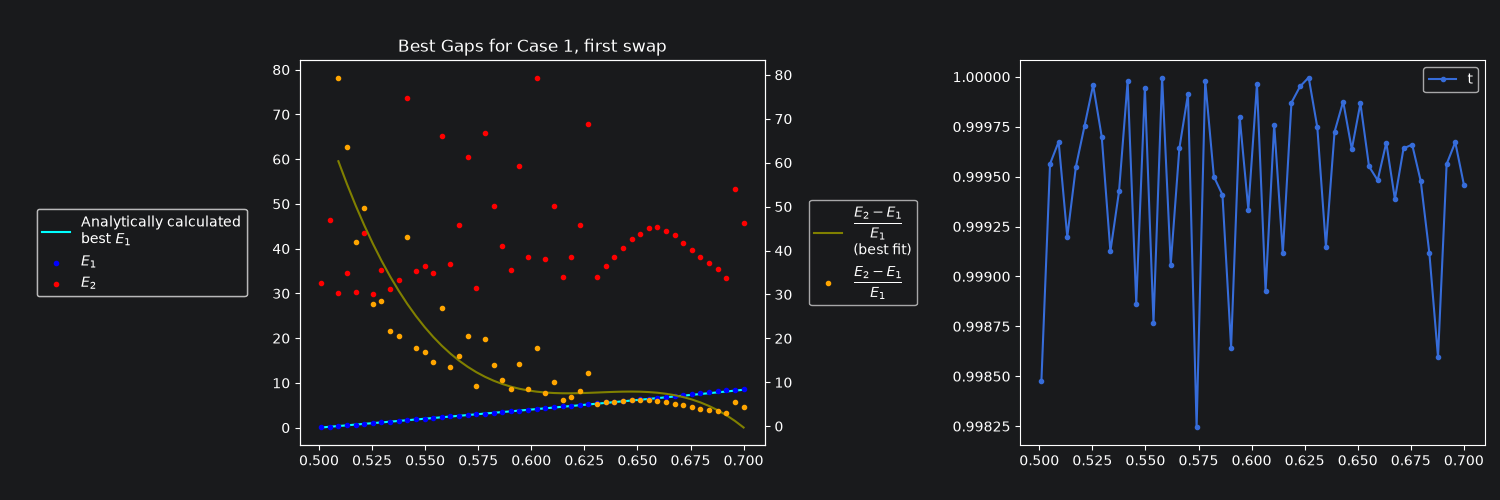

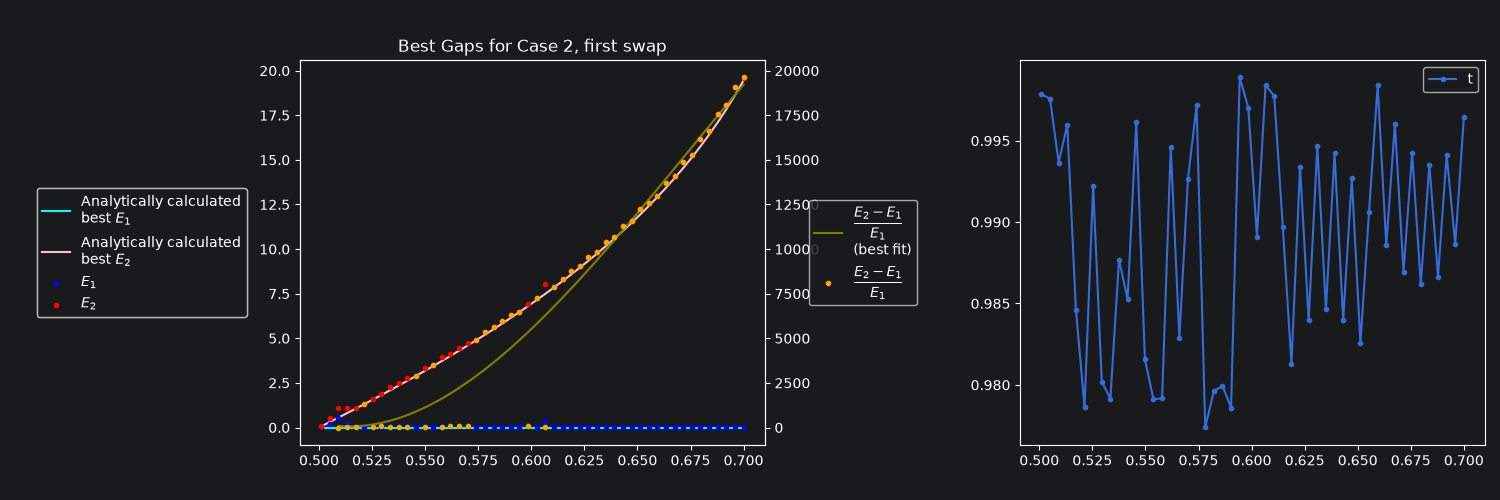

In [4]:
from types import MappingProxyType
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}


colourmap_analytical = MappingProxyType({"E1": ("cyan", "blue"), "E2": ("pink", "red"), "ratio": ("olive", "orange")})
colourmap_experimental = MappingProxyType({"E1": ("paleturquoise", "cornflowerblue"), "E2": ("thistle", "salmon"), "ratio": ("wheat", "yellow")})


def plot_best_gaps(best_gaps: list[tuple[float, float, float, float, float]], title: str, analytical: Callable[[float], tuple[float, float]] | None = None, fig=None, markers='.',
                   colourmap: MappingProxyType[str, str | tuple[str, str]] = colourmap_analytical, suffix="") -> Figure:
    alphas, gap1s, gap2s, energies, t = zip(*best_gaps)
    idx = np.isfinite(gap1s)
    alphas, gap1s, gap2s, energies, t = zip(*np.array(best_gaps)[idx])

    ax, axt, ax2 = None, None, None
    energy_handles, ratio_handles = [], []

    if fig is None:
        fig, (ax, axt) = plt.subplots(1, 2, figsize=(15, 5))
    else:
        (ax, axt, ax2) = fig.get_axes()
        energy_handles, _ = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ratio_handles, _ = ax2.get_legend_handles_labels()
        ax2.get_legend().remove()

    #ax.set_yscale("log")
    if analytical is not None:
        e1, e2 = zip(*[analytical(alpha) for alpha in alphas])
        if not np.isnan(e1).all():
            e1a, = ax.plot(alphas, e1, label="Analytically calculated\nbest $E_1$", color=colourmap["E1"][0])
            energy_handles.append(e1a)
        if not np.isnan(e2).all():
            e2a, = ax.plot(alphas, e2, label="Analytically calculated\nbest $E_2$", color=colourmap["E2"][0])
            energy_handles.append(e2a)
    e1r = ax.scatter(alphas, gap1s, marker=markers, label=r"$E_1$" + suffix, color=colourmap["E1"][1], zorder=5)
    e2r = ax.scatter(alphas, np.array(gap2s) + np.array(gap1s), marker=markers, label=r"$E_2$" + suffix, color=colourmap["E2"][1], zorder=5)
    energy_handles.extend([e1r, e2r])

    if ax2 is None:
        ax2 = ax.twinx()
    gap_ratio = np.array(gap2s) / np.array(gap1s)
    poly = np.polynomial.polynomial.Polynomial.fit(alphas[2:], gap_ratio[2:], 3)
    r = ax2.scatter(alphas[2:], gap_ratio[2:], marker=markers, label="$\\dfrac{E_2-E_1}{E_1}$" + suffix, color=colourmap["ratio"][1], zorder=5)
    rfit, = ax2.plot(alphas[2:], poly(alphas[2:]), label="$\\dfrac{E_2-E_1}{E_1}$\n(best fit)" + suffix, color=colourmap["ratio"][0])
    ratio_handles.extend([rfit, r])

    curr_tit = ax.get_title()
    ax.set_title(curr_tit + (" + " if len(curr_tit) != 0 else "") + title)

    leg1 = ax.legend(handles=energy_handles, loc='center right', bbox_to_anchor=(-0.1, 0.5))
    ax.add_artist(leg1)

    ax2.legend(handles=ratio_handles, loc='center left', bbox_to_anchor=(1.08, 0.5))

    axt.plot(alphas, t, marker='.', label=r"t")
    axt.legend()
    plt.subplots_adjust(left=0.2, right=0.99, wspace=0.55)
    return fig


plot_best_gaps(best_gaps11, "Best Gaps for Case 1, first swap", analytical=an.case1_first_analytical)
plt.show()

#fig = plot_best_gaps(best_gaps12, "Best Gaps for Case 1, second swap")
#plot_best_gaps(best_gaps_exp, "Best Gaps for Experimental Case", fig=fig, markers='+', colourmap=colourmap_experimental, suffix="\n(Experimental)")
#plt.show()

plot_best_gaps(best_gaps21, "Best Gaps for Case 2, first swap", analytical=an.case2_first_analytical)
plt.show()

#fig = plot_best_gaps(best_gaps22, "Best Gaps for Case 2, second swap")
#plot_best_gaps(best_gaps_exp, "Best Gaps for Experimental Case", fig=fig, markers='+', colourmap=colourmap_experimental, suffix="\n(Experimental)")
#plt.show()


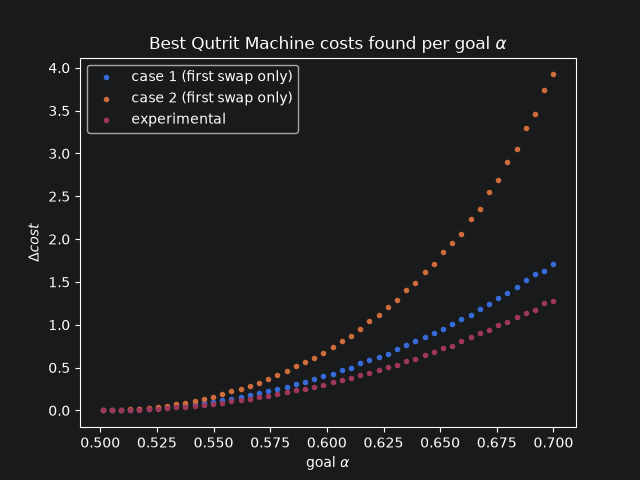

In [5]:
alphas11, _, _, energies11, _ = zip(*best_gaps11)
#alphas12, _, _, energies12, _ = zip(*best_gaps12)
alphas21, _, _, energies21, _ = zip(*best_gaps21)
#alphas22, _, _, energies22, _ = zip(*best_gaps22)
alphas_exp, _, _, energies_exp, _ = zip(*best_gaps_exp)
ax = plt.gca()
#ax.set_yscale('log')
ax.scatter(alphas11, energies11, marker='.', label=r"case 1 (first swap only)")
#ax.scatter(alphas12, energies12, marker='x', label=r"case 1 (both swaps)")
ax.scatter(alphas21, energies21, marker='.', label=r"case 2 (first swap only)")
#ax.scatter(alphas22, energies22, marker='+', label=r"case 2 (both swaps)")
ax.scatter(alphas_exp, energies_exp, marker='.', label=r"experimental")

ax.set_ylabel(r"$\Delta cost$")
ax.set_xlabel(r"goal $\alpha$")
plt.title(r'Best Qutrit Machine costs found per goal $\alpha$')
ax.legend()

plt.show()